# Part 5 | IMAPA — Intermittent Multiple Aggregation Prediction Algorithm
**Guided forecasting tutorial · From manual calculations to Python**

Prerequisites: Croston, SBA, TSB and ADIDA. This lesson uses the same monthly spare-part history as the previous notebooks. We first solve a transparent SES-based version, then explore mixed forecasting models, combination rules and validation.

## 1. Why IMAPA?
ADIDA aggregates at one level, forecasts, and disaggregates. IMAPA repeats this at multiple levels and combines forecasts expressed in the same original units. Lower levels preserve timing information; higher levels reduce zeros and short-term fluctuations but leave fewer observations.

| ADIDA | IMAPA |
|---|---|
| Single aggregation level | Multiple aggregation levels |
| One forecast | Several forecasts |
| Disaggregate | Disaggregate each, then combine |

Teaching choices: fixed alpha = 0.2, first-observation SES initialization, non-overlapping buckets aligned to the most recent observation, equal disaggregation and arithmetic mean. These are not mandatory settings of the full IMAPA algorithm.

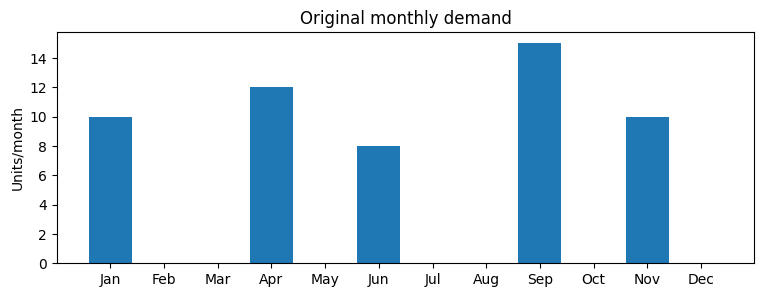

,Month,Demand
0,Jan,10.0
1,Feb,0.0
2,Mar,0.0
3,Apr,12.0
4,May,0.0
5,Jun,8.0
6,Jul,0.0
7,Aug,0.0
8,Sep,15.0
9,Oct,0.0


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
demand = np.array([10,0,0,12,0,8,0,0,15,0,10,0], dtype=float)
alpha = 0.2
plt.figure(figsize=(9,3)); plt.bar(months,demand); plt.ylabel('Units/month'); plt.title('Original monthly demand'); plt.show()
display(pd.DataFrame({'Month':months,'Demand':demand}))

## 2. Demand classification
$$ADI=\frac{12}{5}=2.4,\qquad CV^2=\frac{s^2}{\bar{x}^2}=\frac{7}{121}=0.05785$$
Only positive observations are used for CV²; sample variance is used. The five positive values are 10, 12, 8, 15, 10. With ADI ≥ 1.32 and CV² < 0.49 this is intermittent demand. There are seven zero months and total demand is 55.

In [2]:
def classify(x):
    x=np.asarray(x); pos=x[x>0]
    adi=len(x)/len(pos) if len(pos) else np.inf
    cv=np.var(pos,ddof=1)/np.mean(pos)**2 if len(pos)>1 else np.nan
    label=('Intermittent' if cv<.49 else 'Lumpy') if adi>=1.32 else ('Smooth' if cv<.49 else 'Erratic')
    return adi,cv,label if np.isfinite(cv) else 'Insufficient positive observations'
print(classify(demand))

(2.4, np.float64(0.05785123966942149), 'Intermittent')


## 3. Temporal aggregation from scratch
Let $k$ denote the number of original periods per bucket. For complete aligned buckets,
$$A_j^{(k)}=\sum_{i=1}^k D_{(j-1)k+i}.$$

- k=1: original monthly observations.
- k=2: Jan–Feb = 10+0=10; Mar–Apr = 0+12=12; May–Jun = 0+8=8; Jul–Aug = 0; Sep–Oct = 15; Nov–Dec = 10.
- k=3: Jan–Mar = 10; Apr–Jun = 20; Jul–Sep = 15; Oct–Dec = 10.

Each series totals 55. The number of zeros decreases from seven to one to zero.

k=1: [10.  0.  0. 12.  0.  8.  0.  0. 15.  0. 10.  0.], zeros=7, ADI/CV²/class=(2.4, np.float64(0.05785123966942149), 'Intermittent')


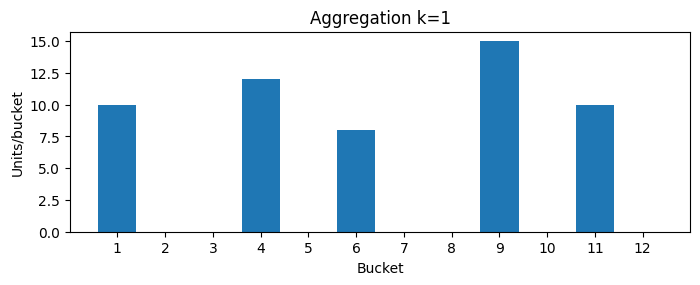

k=2: [10. 12.  8.  0. 15. 10.], zeros=1, ADI/CV²/class=(1.2, np.float64(0.05785123966942149), 'Smooth')


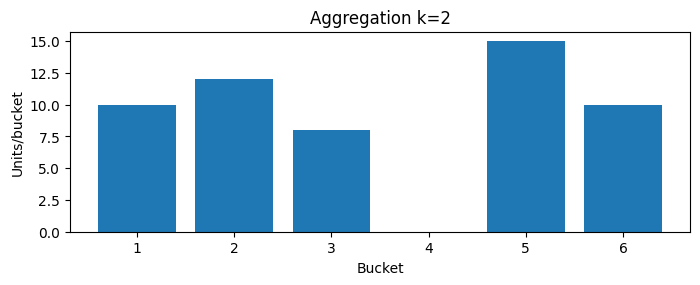

k=3: [10. 20. 15. 10.], zeros=0, ADI/CV²/class=(1.0, np.float64(0.12121212121212122), 'Smooth')


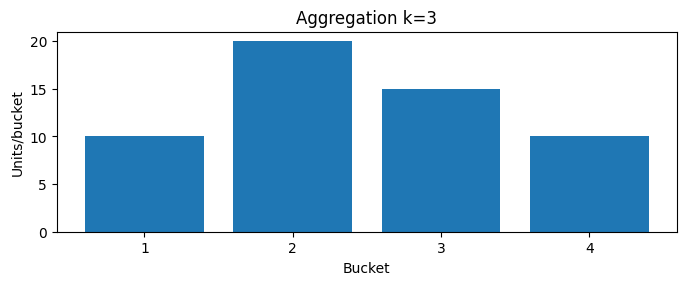

In [3]:
def aggregate(x,k):
    x=np.asarray(x,dtype=float)
    if x.ndim!=1 or not np.all(np.isfinite(x)) or np.any(x<0): raise ValueError('Use finite nonnegative demand')
    if not isinstance(k,(int,np.integer)) or not 1<=k<=len(x): raise ValueError('Invalid k')
    return x[len(x)%k:].reshape(-1,k).sum(axis=1)
for k in [1,2,3]:
    a=aggregate(demand,k)
    print(f'k={k}: {a}, zeros={sum(a==0)}, ADI/CV²/class={classify(a)}')
    plt.figure(figsize=(8,2.6)); plt.bar(range(1,len(a)+1),a); plt.xticks(range(1,len(a)+1)); plt.xlabel('Bucket'); plt.ylabel('Units/bucket'); plt.title(f'Aggregation k={k}'); plt.show()

## 4. Forecast at each aggregation level using SES
$$L_j=\alpha A_j+(1-\alpha)L_{j-1}$$
Initialize $L_1=A_1$. Unlike Croston, SES updates even when a bucket contains zero. The level after observing bucket j is the forecast for the next bucket, not the forecast made before observing j.

### Level 1: k=1
January initializes L=10. February: 0.2(0)+0.8(10)=8. March: 0.2(0)+0.8(8)=6.4. April: 0.2(12)+0.8(6.4)=7.52.

| Month | Actual | Previous level | New level |
|---|---:|---:|---:|
| Jan | 10 | — | 10 |
| Feb | 0 | 10 | 8 |
| Mar | 0 | 8 | 6.4 |
| Apr | 12 | 6.4 | 7.52 |
| May | 0 | 7.52 | 6.016 |
| Jun | 8 | 6.016 | 6.4128 |
| Jul | 0 | 6.4128 | 5.13024 |
| Aug | 0 | 5.13024 | 4.104192 |
| Sep | 15 | 4.104192 | 6.283354 |
| Oct | 0 | 6.283354 | 5.026683 |
| Nov | 10 | 5.026683 | 6.021346 |
| Dec | 0 | 6.021346 | 4.817077 |

Final monthly forecast: 4.817077 / 1 = 4.817077.

,Bucket,Actual,Previous level,Updated level
0,1,10.0,NaN,10.000000
1,2,0.0,10.000000,8.000000
2,3,0.0,8.000000,6.400000
3,4,12.0,6.400000,7.520000
4,5,0.0,7.520000,6.016000
5,6,8.0,6.016000,6.412800
6,7,0.0,6.412800,5.130240
7,8,0.0,5.130240,4.104192
8,9,15.0,4.104192,6.283354
9,10,0.0,6.283354,5.026683


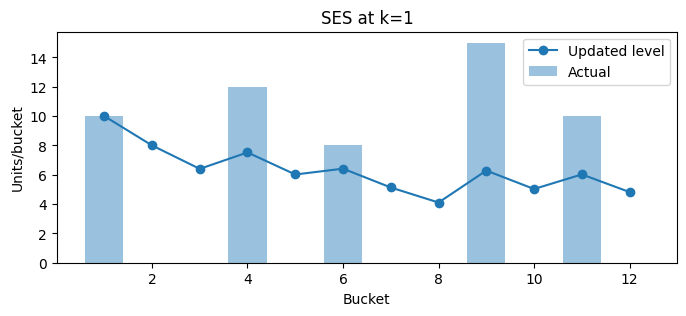

Monthly forecast: 4.817077 / 1 = 4.817077


In [4]:
def ses(x,alpha=.2):
    x=np.asarray(x,dtype=float)
    if not len(x) or not 0<alpha<=1: raise ValueError('Invalid series or alpha')
    levels=[x[0]]
    for v in x[1:]: levels.append(alpha*v+(1-alpha)*levels[-1])
    return np.array(levels)
def show_level(k):
    a=aggregate(demand,k); l=ses(a,alpha)
    display(pd.DataFrame({'Bucket':np.arange(1,len(a)+1),'Actual':a,'Previous level':np.r_[np.nan,l[:-1]],'Updated level':l}).round(6))
    plt.figure(figsize=(8,3)); plt.bar(range(1,len(a)+1),a,alpha=.45,label='Actual'); plt.plot(range(1,len(a)+1),l,'o-',label='Updated level'); plt.xlabel('Bucket'); plt.ylabel('Units/bucket'); plt.title(f'SES at k={k}'); plt.legend(); plt.show()
    print(f'Monthly forecast: {l[-1]:.6f} / {k} = {l[-1]/k:.6f}')
show_level(1)

### Level 2: k=2
The actual bucket totals are 10, 12, 8, 0, 15, 10.

$$L_1=10$$
$$L_2=.2(12)+.8(10)=10.4$$
$$L_3=.2(8)+.8(10.4)=9.92$$
$$L_4=.2(0)+.8(9.92)=7.936$$
$$L_5=.2(15)+.8(7.936)=9.3488$$
$$L_6=.2(10)+.8(9.3488)=9.47904$$

This is a forecast for two months. Divide by 2 to get **4.73952 units/month**.

,Bucket,Actual,Previous level,Updated level
0,1,10.0,NaN,10.00000
1,2,12.0,10.0000,10.40000
2,3,8.0,10.4000,9.92000
3,4,0.0,9.9200,7.93600
4,5,15.0,7.9360,9.34880
5,6,10.0,9.3488,9.47904


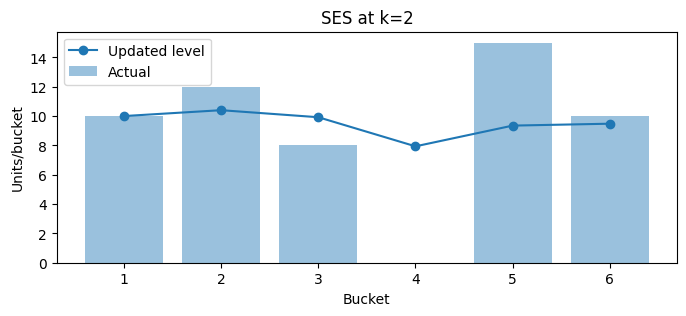

Monthly forecast: 9.479040 / 2 = 4.739520


In [5]:
show_level(2)

### Level 3: k=3
This is our previous ADIDA example.
$$L_1=10$$
$$L_2=.2(20)+.8(10)=12$$
$$L_3=.2(15)+.8(12)=12.6$$
$$L_4=.2(10)+.8(12.6)=12.08$$
Disaggregate: 12.08 / 3 = **4.026667 units/month**.

,Bucket,Actual,Previous level,Updated level
0,1,10.0,NaN,10.00
1,2,20.0,10.0,12.00
2,3,15.0,12.0,12.60
3,4,10.0,12.6,12.08


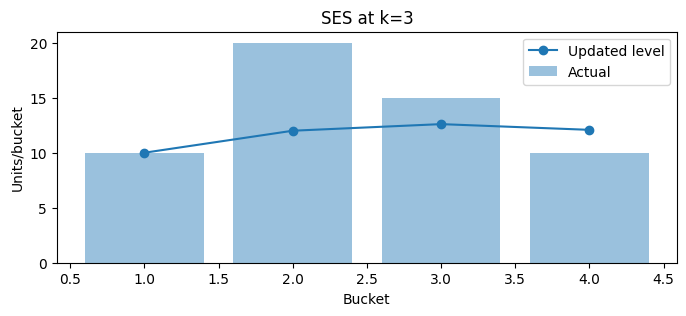

Monthly forecast: 12.080000 / 3 = 4.026667


In [6]:
show_level(3)

## 5. Combine the forecasts
Always disaggregate before combining: otherwise we would average incompatible units.
$$F^{(k)}=L_{last}^{(k)}/k$$
$$F_{IMAPA}=\frac{1}{|K|}\sum_{k\in K}F^{(k)}$$
$$F_{IMAPA}=\frac{4.817077+4.739520+4.026667}{3}=4.527755$$
This is an expected monthly demand rate, not a prediction of exact order timing. With no new observations, the SES-based forecast remains flat; three months total approximately 13.5833 units.

,k,buckets,zeros,ADI,CV2,category,aggregated_forecast,monthly_forecast
0,1,12,7,2.4,0.057851,Intermittent,4.817077,4.817077
1,2,6,1,1.2,0.057851,Smooth,9.479040,4.739520
2,3,4,0,1.0,0.121212,Smooth,12.080000,4.026667


IMAPA: 4.527754569955556


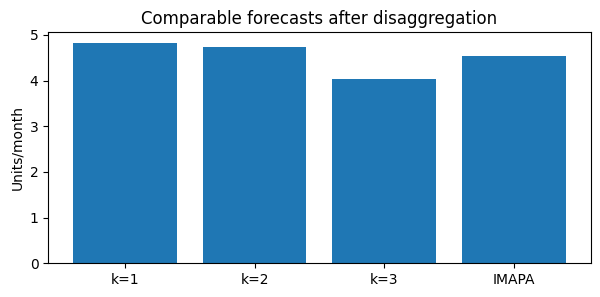

In [7]:
def imapa(x,levels=(1,2,3),alpha=.2,combine='mean',weights=None):
    if not levels or len(set(levels))!=len(levels): raise ValueError('Use unique nonempty levels')
    rows=[]
    for k in levels:
        a=aggregate(x,k); l=ses(a,alpha)[-1]
        adi,cv,category=classify(a)
        rows.append(dict(k=k,buckets=len(a),zeros=int(sum(a==0)),ADI=adi,CV2=cv,category=category,aggregated_forecast=l,monthly_forecast=l/k))
    df=pd.DataFrame(rows); f=df.monthly_forecast.to_numpy()
    if combine=='mean': result=f.mean()
    elif combine=='median': result=np.median(f)
    elif combine=='weighted':
        w=np.asarray(weights,dtype=float)
        if w.shape!=f.shape or not np.all(np.isfinite(w)) or np.any(w<0) or not np.isclose(w.sum(),1): raise ValueError('Weights must be nonnegative and sum to one')
        result=w@f
    else: raise ValueError('Unknown combination')
    return float(result),df
f,details=imapa(demand)
display(details.round(6)); print('IMAPA:',f)
plt.figure(figsize=(7,3)); plt.bar(['k=1','k=2','k=3','IMAPA'],[*details.monthly_forecast,f]); plt.ylabel('Units/month'); plt.title('Comparable forecasts after disaggregation'); plt.show()

## 6. Process diagram
The same history flows through three independent aggregation and forecasting branches. Only after returning to monthly units do the branches merge.

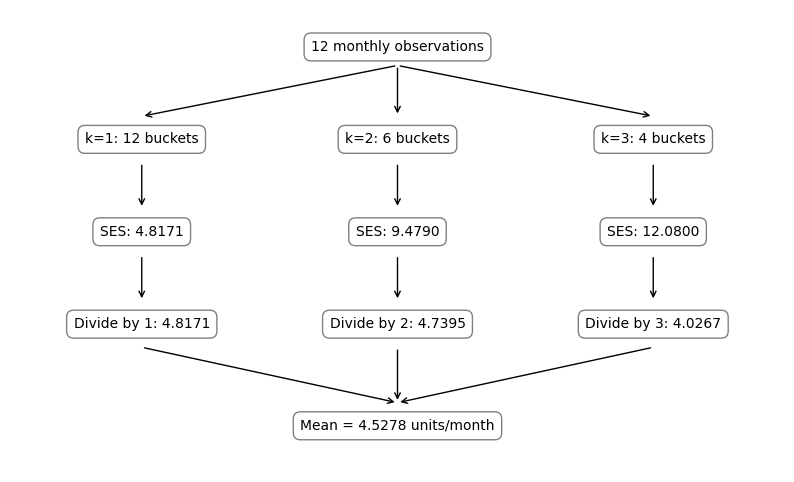

In [8]:
fig,ax=plt.subplots(figsize=(10,6)); ax.axis('off'); ax.set_xlim(0,1); ax.set_ylim(0,1)
def box(x,y,t): ax.text(x,y,t,ha='center',va='center',bbox=dict(boxstyle='round,pad=.5',fc='white',ec='0.5'))
def arrow(x,y,x2,y2): ax.annotate('',xy=(x2,y2),xytext=(x,y),arrowprops=dict(arrowstyle='->'))
box(.5,.92,'12 monthly observations')
for x,r in zip([.17,.5,.83],details.itertuples()):
    arrow(.5,.88,x,.77); box(x,.72,f'k={r.k}: {r.buckets} buckets'); arrow(x,.67,x,.57); box(x,.52,f'SES: {r.aggregated_forecast:.4f}'); arrow(x,.47,x,.37); box(x,.32,f'Divide by {r.k}: {r.monthly_forecast:.4f}'); arrow(x,.27,.5,.15)
box(.5,.1,f'Mean = {f:.4f} units/month'); plt.show()

## 7. Choosing aggregation levels
With 12 periods, k=4 leaves only three buckets and k=6 leaves two. A useful teaching guardrail is at least four complete buckets and two positive buckets, giving $k_{max}=\lfloor12/4\rfloor=3$. This is not a universal optimum. If history has 14 observations and k=3, our implementation drops the oldest two observations, keeping the latest 12. Do not replace missing observations with zeros: they are not equivalent.

Higher aggregation can reduce intermittency but cannot guarantee accuracy.

In [9]:
_,wide=imapa(demand,(1,2,3,4,6))
display(wide.round(6))
print('Eligible levels:',[k for k in range(1,len(demand)+1) if len(aggregate(demand,k))>=4 and sum(aggregate(demand,k)>0)>=2])
print('14-period alignment example:',aggregate(np.arange(1,15),3))

,k,buckets,zeros,ADI,CV2,category,aggregated_forecast,monthly_forecast
0,1,12,7,2.4,0.057851,Intermittent,4.817077,4.817077
1,2,6,1,1.2,0.057851,Smooth,9.479040,4.739520
2,3,4,0,1.0,0.121212,Smooth,12.080000,4.026667
3,4,3,0,1.0,0.244959,Smooth,20.360000,5.090000
4,6,2,0,1.0,0.016529,Smooth,29.000000,4.833333


Eligible levels: [1, 2, 3]
14-period alignment example: [12. 21. 30. 39.]


## 8. Mean, median and weighted combination
Mean: 4.527755. Median: sort the rates and select the middle, 4.739520. Weighted average: assign weights 0.2, 0.3, 0.5 to k=1,2,3 respectively.
$$F_w=.2(4.817077)+.3(4.739520)+.5(4.026667)=4.398605$$
Weights are illustrative; estimate them using past validation data, not the test set.

Mean        4.527755
Median      4.739520
Weighted    4.398605
Name: Units/month, dtype: float64

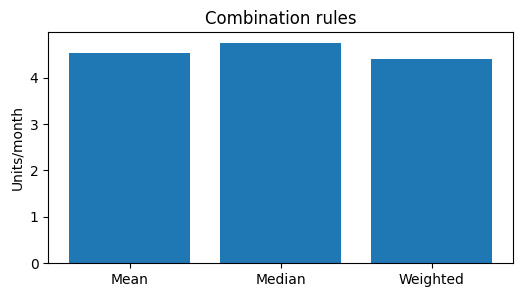

In [10]:
methods={'Mean':imapa(demand)[0],'Median':imapa(demand,combine='median')[0],'Weighted':imapa(demand,combine='weighted',weights=[.2,.3,.5])[0]}
display(pd.Series(methods,name='Units/month')); plt.figure(figsize=(6,3)); plt.bar(methods.keys(),methods.values()); plt.ylabel('Units/month'); plt.title('Combination rules'); plt.show()

## 9. Mixed models: connect back to Croston, SBA and TSB
The full IMAPA approach can choose models at each aggregation level. Our transparent illustration chooses SBA for k=1 (intermittent), and SES for k=2 and k=3 (smooth). This is not a reproduction of the original automatic model-selection and optimization procedure. Note that k=2 has the same positive quantities as k=1, so its CV² is exactly the same (0.05785), although its ADI changes to 1.2.

Croston updates size Z and interval P only on positive demand. SBA multiplies Z/P by (1−alpha/2). TSB updates occurrence probability every period and multiplies by Z. Initialize Z=first positive demand, P=number of periods through first positive demand and p=1/P, consistent with our example.

Historical mean    4.583333
Croston            5.801382
SBA                5.221244
TSB                4.668017
ADIDA k=3          4.026667
IMAPA SES          4.527755
IMAPA mixed        4.662477
Name: Units/month, dtype: float64

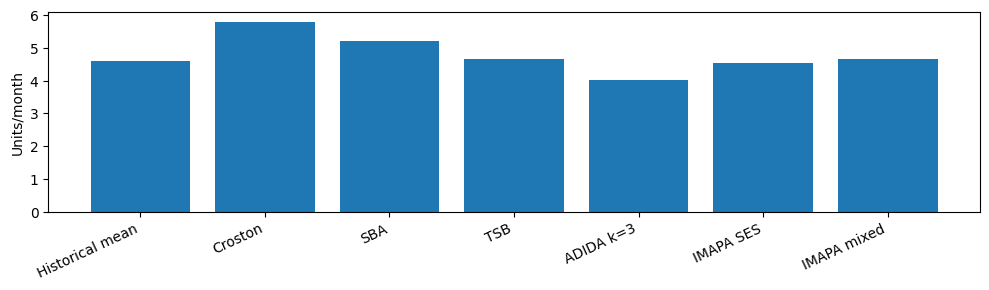

In [11]:
def intermittent(x,alpha=.2,beta=.2):
    x=np.asarray(x); hits=np.flatnonzero(x>0)
    if not len(hits): return dict(Croston=0.,SBA=0.,TSB=0.)
    last=hits[0]; z=x[last]; p=last+1.; prob=1/p
    for i in range(last+1,len(x)):
        d=x[i]; prob=(1-beta)*prob+beta*(d>0)
        if d>0:
            z=(1-alpha)*z+alpha*d; p=(1-alpha)*p+alpha*(i-last); last=i
    return dict(Croston=z/p,SBA=(1-alpha/2)*z/p,TSB=z*prob)
base=intermittent(demand)
mixed=np.mean([base['SBA'],details.monthly_forecast.iloc[1],details.monthly_forecast.iloc[2]])
comparison={'Historical mean':demand.mean(),**base,'ADIDA k=3':imapa(demand,(3,))[0],'IMAPA SES':f,'IMAPA mixed':mixed}
display(pd.Series(comparison,name='Units/month').round(6)); plt.figure(figsize=(10,3)); plt.bar(comparison.keys(),comparison.values()); plt.xticks(rotation=25,ha='right'); plt.ylabel('Units/month'); plt.tight_layout(); plt.show()

## 10. Experiment with alpha and aggregation levels
Edit the parameters in the next cell and rerun. Select k=3 only to recover ADIDA, or try the median. Levels with very few buckets are for experimentation, not reliable estimation.

,k,buckets,zeros,ADI,CV2,category,aggregated_forecast,monthly_forecast
0,1,12,7,2.4,0.0579,Intermittent,4.8171,4.8171
1,2,6,1,1.2,0.0579,Smooth,9.4790,4.7395
2,3,4,0,1.0,0.1212,Smooth,12.0800,4.0267


Final: 4.527754569955556


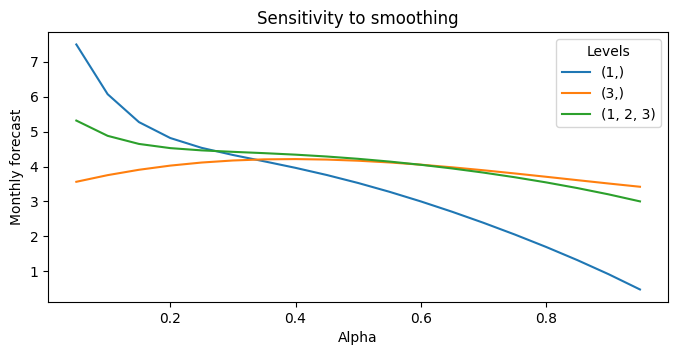

In [12]:
experiment_levels=(1,2,3)
experiment_alpha=.2
experiment_combination='mean'
value,table=imapa(demand,experiment_levels,experiment_alpha,experiment_combination)
display(table.round(4)); print('Final:',value)
plt.figure(figsize=(8,3.5))
for levels in [(1,),(3,),(1,2,3)]:
    alphas=np.linspace(.05,.95,19); plt.plot(alphas,[imapa(demand,levels,a)[0] for a in alphas],label=str(levels))
plt.xlabel('Alpha'); plt.ylabel('Monthly forecast'); plt.legend(title='Levels'); plt.title('Sensitivity to smoothing'); plt.show()

## 11. Rolling-origin backtesting
At each origin, train using only months already observed and compare the next forecast with the next actual. For this tiny dataset use origins 8–11 and k=1,2, ensuring four complete buckets for k=2. This is a mechanics demonstration, not evidence of superiority. Evaluate MAE and signed bias (forecast minus actual). For intermittent demand, MAPE is undefined at zero actuals; also evaluate cumulative demand over inventory lead times. Tune on validation origins and reserve a separate test period in real projects.

In [13]:
records=[]
for t in range(8,len(demand)):
    train=demand[:t]; actual=demand[t]
    forecasts={'Mean':train.mean(),**intermittent(train),'ADIDA k=2':imapa(train,(2,))[0],'IMAPA k=1,2':imapa(train,(1,2))[0]}
    for model,forecast in forecasts.items(): records.append((months[t],model,actual,forecast))
back=pd.DataFrame(records,columns=['Month','Model','Actual','Forecast']); back['Error']=back.Forecast-back.Actual; back['Absolute error']=back.Error.abs()
display(back.pivot(index='Month',columns='Model',values='Forecast').round(3)); display(back.groupby('Model').agg(MAE=('Absolute error','mean'),Bias=('Error','mean')).round(3))

Model,ADIDA k=2,Croston,"IMAPA k=1,2",Mean,SBA,TSB
Month,,,,,,
Dec,3.326,5.801,4.674,5.00,5.221,5.835
Nov,4.674,6.022,4.851,4.50,5.420,4.687
Oct,2.908,6.022,4.596,5.00,5.420,5.859
Sep,3.968,6.526,4.036,3.75,5.874,4.163


,MAE,Bias
Model,,
ADIDA k=2,5.648,-2.531
Croston,6.069,-0.157
"IMAPA k=1,2",6.346,-1.711
Mean,6.688,-1.688
SBA,6.087,-0.766
TSB,6.961,-1.114


## 12. Practice questions with worked solutions
1. **What is the k=2 series?** Pair consecutive months: [10,12,8,0,15,10]. Total 55.
2. **What happens at the zero bucket for k=2?** SES updates from 9.92 to .8×9.92=7.936.
3. **Why divide 12.08 by 3?** It represents three months; equal disaggregation gives 4.026667 units/month.
4. **What if only k=3 is selected?** The result is identical to ADIDA with the same settings.
5. **What is the median combination?** Sort 4.026667, 4.739520, 4.817077; the middle is 4.739520.
6. **Can we choose k=6?** Mathematically yes, but only two buckets remain, violating our four-bucket guardrail.
7. **Does a lower forecast guarantee better accuracy?** No. Compare out-of-sample performance and inventory impact.

## 13. Revision and limitations
IMAPA combines forecasts at different temporal scales; it does not predict exact demand events. It may improve robustness but loses timing detail at larger levels and costs more computation. For this example, the monthly forecast is 4.5278, the next three months total 13.5833 and the next 12 months total 54.3331, assuming no new observations and a flat rate. Mixed-model illustration gives 4.6625.

Reference: Petropoulos and Kourentzes (2015), *Forecast combinations for intermittent demand*, Journal of the Operational Research Society, 66, 914–924. https://doi.org/10.1057/jors.2014.62

Next lesson: probability distributions for demand forecasting (Poisson, Gamma, Negative Binomial), leading to Tweedie.

In [14]:
assert np.isclose(f,4.527754569955556)
assert np.isclose(imapa(demand,(3,))[0],12.08/3)
assert np.isclose(base['TSB'],4.668016573546499)
assert np.isclose(classify(aggregate(demand,2))[1],classify(demand)[1])
assert all(aggregate(demand,k).sum()==55 for k in (1,2,3,4,6))
print('All numerical checks passed.')

All numerical checks passed.
